# The H100 NVL as seen by a DSMEM kernel: memory, network, TMA, synchronisation and collectives

This report characterises one NVIDIA H100 NVL from our own microbenchmarks. It is written for someone who wants to design kernels around **distributed shared memory (DSMEM)**, the ability of the thread blocks of a cluster to read and write each other's shared memory over the SM-to-SM network. It answers five questions, one per section:

1. **Memory hierarchy.** How far away are L1, L2 and HBM, in cycles and in bandwidth? Where does DSMEM fit in that ladder?
2. **DSMEM.** What does a remote shared-memory access cost? Does it depend on the cluster size or on which SMs talk? How much data can an SM send and receive?
3. **TMA.** What does a bulk asynchronous copy cost, to issue and to complete, and how large should a copy be?
4. **Synchronisation.** What do barriers, fences, mbarriers and flags cost, and what is the cheapest way to hand data from one SM to another?
5. **Collectives.** Where do the cycles of a cluster-level AllReduce, AllGather or AlltoAll go, seen from one SM?

The last section combines everything. It splits the measured time of each round of a collective into the costs of the primitives that the round executes, all measured in isolation in sections 1–4.

**Reading guide.** Every section starts with the background needed to read it, then explains briefly how we measured, then shows the figures and what they imply for kernel design. All times are **SM cycles at the locked 1635 MHz clock** (1 cycle = 0.61 ns); some figures add a nanosecond axis. The summary table below collects the numbers worth remembering.

In [1]:
%matplotlib inline
import pandas as pd
from h100char import style, summary as S, figs_mem_tma as A, figs_dsmem_sync as D, figs_coll as C, breakdown as B
pd.set_option("display.max_colwidth", 90)

## 0. Device and method

**The device.** An H100 NVL (GH100, PCIe card): 132 SMs in 66 TPCs (two SMs per TPC) and 8 GPCs, 228 KiB of shared memory/L1 per SM, a 60 MiB L2 split into two partitions, and 94 GB of HBM3 with a 3.94 TB/s theoretical peak. We used two cards of this model. Card A was used for topology, memory hierarchy, TMA and synchronisation; card B for everything DSMEM and the collectives. Both cards have the same SM→GPC map and the same cluster placement and occupancy, measured on each. One difference matters only for global-memory locality: the pairs of GPCs that share an L2 partition differ (GPCs 4 and 7 swap partitions). The near/far costs are the same.

**Fixed configuration.** SM clock locked at 1635 MHz, the highest clock this card sustains under the heaviest kernels of the study. HBM at its default 2619 MHz, power limit 400 W, ECC on, CUDA 12.9 (`sm_90a`). Launches whose clock dropped below the lock were discarded and counted in each experiment; in the data shown here this happened only in a few heavy atomic-throughput kernels.

**How we measure.** Latencies are dependent chains (each access needs the previous result), timed with `%clock64` on the SM that issues them, with the timer cost subtracted. Bandwidths use thousands of threads, either per SM (bytes per cycle from `%clock64`) or GPU-wide (TB/s from CUDA events, net of the 3.9 µs event overhead). Cross-SM events (hand-offs, collectives) use the global `%globaltimer`. Every block that produces a number records the SM it ran on (`%smid`).

In [2]:
S.device_table()

,card A,card B
GPU,NVIDIA H100 NVL,NVIDIA H100 NVL
SMs,132,132
"SM clock (MHz, locked)",1635,1635
HBM clock (MHz),2619,2619
CUDA,12.9,12.9
driver,580.126.20,580.126.20
L2 clock / SM clock,0.951–0.956,not re-measured
used for,"topology, memory hierarchy, TMA, synchronisation","DSMEM latency, heatmap, bandwidth, atomics, collectives"


The real SM clock under the lock differs slightly between GPCs (1628.5–1634.9 MHz median per GPC, ≤ 0.4 %), and the L2 runs at about 0.95× the SM clock. Cycle counts that cross into L2 or HBM therefore depend a little on the GPC; we report them as counted by the issuing SM and convert to 1635 MHz where it matters.

### Numbers to remember

In [3]:
S.cheat_sheet()

value  \
kind      quantity                                                                                                            
latency   local shared memory load (ld.shared)                                                                           23   
          L1 hit                                                                                                         32   
          remote DSMEM load (any cluster size 2–16)                                                202 (186–222 by SM pair)   
          L2 hit, near / far partition                                                                            270 / 427   
          HBM, near / far partition                                                                               506 / 668   
          one TMA bulk copy (issue → mbarrier completion seen)                                            340 + bytes / 107   
          DSMEM atomic add.u32 / add.f32                                                                     load + 8 / 562   
bandwidth shared memory / L1, per SM                                                                                    128   
          DSMEM send limit per SM (ld, st, st.async, TMA put)                                                         21.33   
          DSMEM receive, one SM fed by ≥ 3 peers                                                                      32–34   
          L2 read, one SM alone / all SMs                                                                           82 / 36   
          GPU-wide: L2 read / HBM read / DSMEM                                                         7.7 / 3.70 / 2.3–4.0   
          TMA engine per SM (global → shared)                                                                           128   
issue     TMA copy issue, one warp / four warps                                                                     48 / 14   
          shared → shared TMA command, ≤ 1 KiB (issue-bound)                                                             66   
sync      __syncthreads (1 / 8 / 32 warps)                                                                      9 / 24 / 85   
          mbarrier arrive.expect_tx / try_wait on a completed phase                                                 38 / 39   
          fence.proxy.async (256 threads)                                                                               157   
          cluster barrier, 256 threads: no prior store / after a store                                            410 / 580   
          hand-off st.async + mbarrier, one way: fast mode / median                                               181 / 266   
          hand-off round trip: st.async / release-acquire flag / global flag                         565 / 1325 / 1962–2126   
placement max active clusters at 1 CTA/SM, CS 2 / 4 / 8 / 16                  66 / 30 / 15 / 7  (idle SMs 0 / 12 / 12 / 20)   

                                                                                            unit  \
kind      quantity                                                                                 
latency   local shared memory load (ld.shared)                                            cycles   
          L1 hit                                                                          cycles   
          remote DSMEM load (any cluster size 2–16)                                       cycles   
          L2 hit, near / far partition                                                    cycles   
          HBM, near / far partition                                                       cycles   
          one TMA bulk copy (issue → mbarrier completion seen)                            cycles   
          DSMEM atomic add.u32 / add.f32                                                  cycles   
bandwidth shared memory / L1, per SM                                                     B/cycle   
          DSMEM send limit per SM (ld, st, st.async, TMA put)        

## 1. Memory hierarchy

### Background
Each SM has one 256 KiB SRAM that is split between **shared memory** (software-managed, up to 227 KiB per block) and the **L1 cache**. Behind it sits the **L2**, 60 MiB shared by all SMs. On this chip the L2 is built as **two partitions**, each attached to four of the eight GPCs. Every 128-byte line has a *home* partition, fixed by its physical address (half of the lines in each). A read from an SM in the other partition is a *far* access: it crosses the link between the partitions. The L2 then keeps a copy in the reader's partition, so the next read from that partition is near again. **HBM** sits behind the L2.

### How we measured latency
A pointer chase: one thread follows a random cycle through a buffer, so each load needs the address returned by the previous one. Sweeping the buffer size (the *footprint*) walks the chase through L1, L2 and HBM. With `ld.global.ca` the loads may hit in L1; `ld.global.cg` skips L1 and starts in L2.

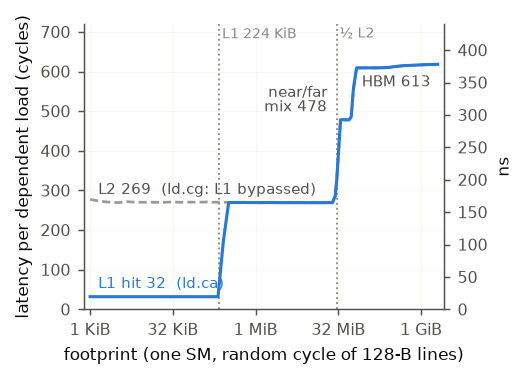

In [4]:
A.fig_latency_footprint();

**What the curve shows.**
- **Three plateaus: L1 at 32 cycles, L2 at 269, HBM at 613.** L1 holds the chase up to about 212 KiB: the whole SRAM minus what the driver reserves when a kernel uses no shared memory.
- **The L2 behaves like a 25–28 MiB cache for one SM, not 60 MiB.** The first step in the L2 range comes at about 28 MiB. Between 35 and 51 MiB the average is 478 cycles: half of the lines are homed in the other partition and are still served from there (far hits), the other half already miss to HBM. This is the cost of the copy-on-read design. Every line a partition reads is stored twice, so the unique capacity seen from one partition is about half the L2.

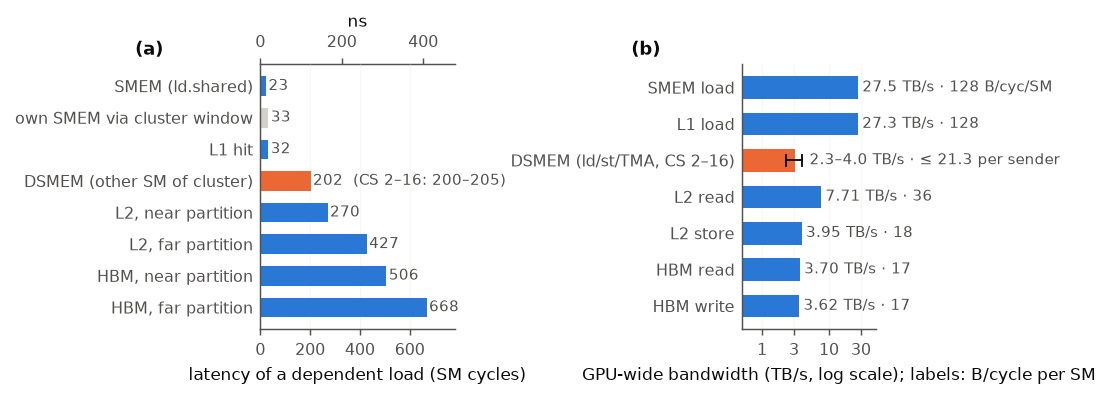

In [5]:
A.fig_ladders();

**(a) Latency ladder.** A remote **DSMEM load costs 202 cycles**. That is about 9× a local shared-memory load (23), 0.75× an L2 hit in the near partition (270) and less than half of a far L2 hit (427). Reading your own shared memory through the cluster address window costs 33 cycles: only the path, not the network, adds 10 cycles.

**(b) Bandwidth ladder.** Shared memory and L1 deliver 128 B/cycle per SM (27.5 TB/s over 132 SMs). The L2 delivers 7.7 TB/s for reads and 4.0 TB/s for stores. HBM delivers 3.70 TB/s (94 % of the theoretical peak). DSMEM traffic over all clusters reaches **2.3–4.0 TB/s**, depending on the operation and the cluster size (section 2). Per SM, an SM can push at most 21.3 B/cycle into the SM-to-SM network. That is a sixth of its shared-memory bandwidth and less than what one SM pulls from L2 on its own (82 B/cycle, figure below).

**Implication.** DSMEM saves *latency* and L2/HBM *capacity*, not aggregate bandwidth. It wins against far L2 hits and HBM, and when data would otherwise make a round trip through L2 between two SMs. It cannot replace L2 as a bulk streaming source.

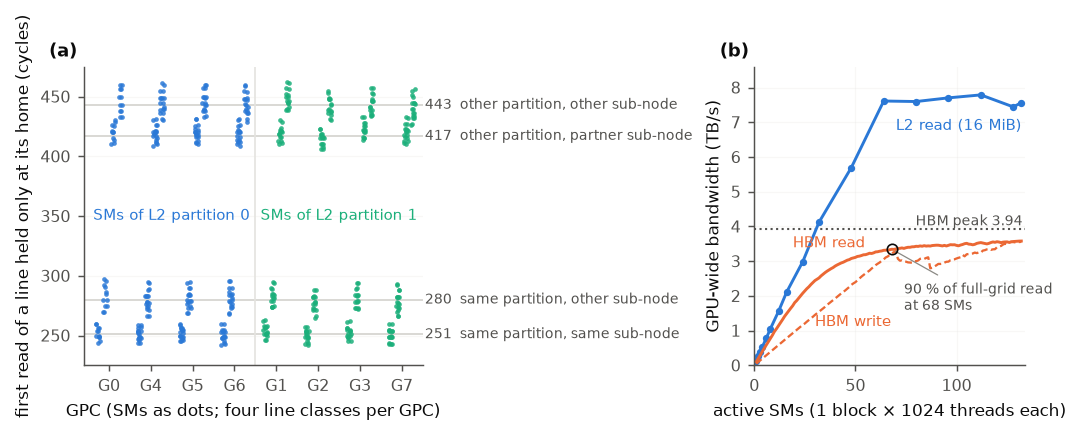

In [6]:
A.fig_l2_nuca();

**(a) The L2 is a 2×2 grid.** We measured the first read of lines that live only at their home, for every SM and every home. Each partition is split into two *sub-nodes* of two GPCs each. A line from the SM's own sub-node costs 251 cycles, the other sub-node of the same partition +29 (280), and the other partition +166 (417, or 443 from the other sub-node there). The cost is a sum of independent terms, and each SM adds a small position term (near hits range over 246–289 cycles across SMs).

**(b) How many SMs are needed to saturate memory.** One SM reads 61 B/cycle from HBM (100 GB/s) and 82 B/cycle from L2. HBM read bandwidth reaches 90 % of its maximum with **68 SMs**. HBM write bandwidth is not monotonic in the SM count (dips at 71 and 87 SMs) and reaches its maximum only with all SMs. The L2 saturates at about 64 SMs.

**What this means for DSMEM kernels.**
- A memory-bound kernel loses little HBM bandwidth if about half of the SMs do something else, such as cluster-level reductions or exchanges, while the rest stream.
- The far-partition penalty (+166 cycles) is larger than the whole advantage of DSMEM over a near L2 hit (68 cycles). Data shared between SMs of different partitions is where moving exchanges from L2 to DSMEM pays most. A cluster always lives inside one GPC, so all its DSMEM traffic stays local.

## 2. Distributed shared memory and the SM-to-SM network

### Background
A **thread-block cluster** is a group of up to 16 thread blocks (CTAs) that the hardware launches together, all at once, on the SMs of **one GPC**. Inside a cluster, every CTA can access the shared memory of every other CTA: `mapa` turns a local shared-memory address into the same address in CTA *r*, and ordinary `ld/st/atom.shared::cluster` instructions (or `cg::cluster_group::map_shared_rank`) access it. These accesses travel over the SM-to-SM network of the GPC, never through L2. Asynchronous variants exist: `st.async` and `red.async` (one store or reduction, completion reported on the receiver's mbarrier) and TMA bulk copies from one CTA's shared memory into another's (section 3).

A cluster cannot span GPCs, so the GPC sizes decide how many clusters fit at once.

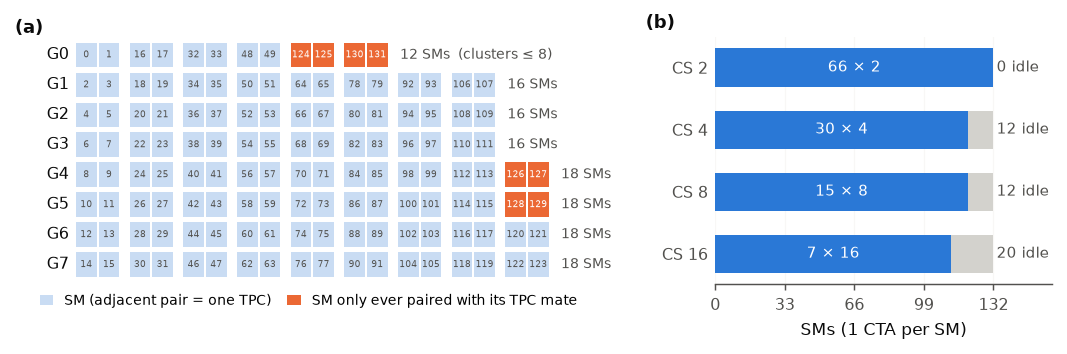

In [7]:
D.fig_gpc_occupancy();

**(a) The chip.** The 8 GPCs have 12, 16, 16, 16, 18, 18, 18 and 18 SMs: the full die has 18 per GPC, and some TPCs are disabled. Eight SMs (124–131, orange) were only ever placed in clusters of 2 together with their TPC mate. They never joined larger clusters, so only 124 SMs can host clusters of 4 or more. Seven GPCs can host a 16-CTA cluster.

**(b) Occupancy with one CTA per SM** (the usual case when a block uses most of the shared memory). CS 2 fills all 132 SMs with 66 clusters. CS 4 and CS 8 leave 12 SMs idle (9 %). **CS 16 leaves 20 SMs idle (15 %)**, because a 16-CTA cluster fits once in each GPC except the 12-SM one. The occupancy API (`cudaOccupancyMaxActiveClusters`) predicted exactly what we measured in every configuration.

### Latency of a remote shared-memory load
**How we measured.** One thread of CTA *i* chases pointers stored in the shared memory of CTA *j* of the same cluster (`ld.shared::cluster`), 1 CTA per SM. We measured every rank pair of clusters of size 2, 4, 8 and 16, under all three cluster-scheduling policies, and recorded the physical SMs of both ends.

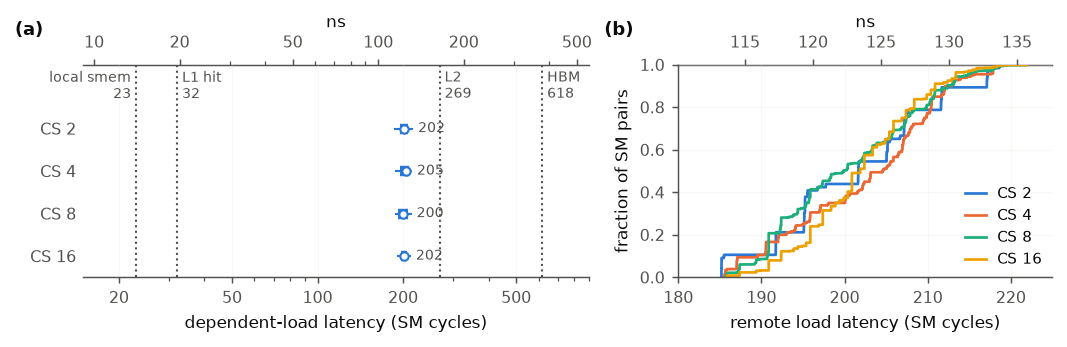

In [8]:
D.fig_dsmem_latency_cs();

**Remote DSMEM latency does not depend on the cluster size:** the median is 202, 205, 200 and 202 cycles for CS 2, 4, 8 and 16, with 90 % of pairs between 185 and 217 cycles at every size (b). The scheduling policy and the access pattern (sequential or random within 16 KiB) change nothing (≤ 0.05 cycles). The ±15-cycle spread comes from which SMs talk, which the next figure resolves.

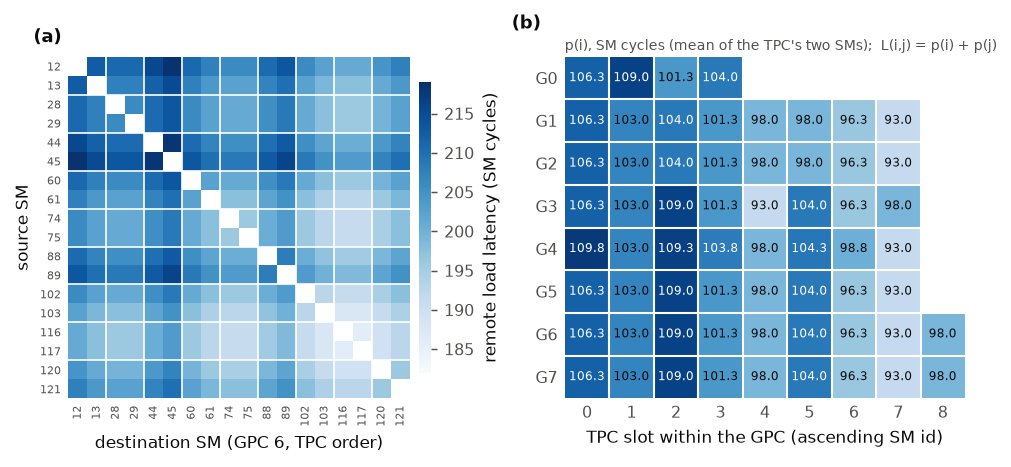

In [9]:
D.fig_dsmem_heatmap();

**(a)** Latency between every pair of SMs of one 18-SM GPC. To reach every pair, we filled all other SMs with placeholder blocks so that the measuring cluster had to land on chosen SMs. Each pair is measured in 20–130 launches, with a spread of less than 0.001 cycles. The matrix is symmetric and has a striped pattern: some SMs are slow both as source and as destination.

**(b)** The whole chip follows one rule exactly: **L(i, j) = p(i) + p(j)**. Each SM contributes a fixed delay p of 93–111.5 cycles, the same whether it sends or receives; the fit leaves a residual of 0.0001 cycles over 1868 SM pairs. The delay depends only on the TPC's slot inside its GPC, with the same pattern repeated across GPCs (G1 = G2, G5 = G6 = G7). Two SMs of the same TPC get no shortcut, and no group of TPCs is closer than any other.

**What this tells us about the network.** Every request and reply goes through one central point per GPC (a crossbar or hub), and each SM sits at a fixed distance from it. For kernel design:
- Placement inside a GPC is worth at most 36 cycles (186 vs 222), about 18 %.
- Neighbouring ranks are not cheaper than distant ranks, so algorithms can choose partners freely.
- The latency is fixed in SM cycles, not nanoseconds: it did not change when the GPC clock varied by 0.5 %.

### Bandwidth
**How we measured.** Thousands of threads per CTA move 16–96 KiB per SM with remote loads, remote stores, `st.async` or TMA bulk puts, in patterns from one-way pairs to rings, fan-in and fan-out. A linear fit of time vs bytes separates the fixed start-up cost from the streaming rate.

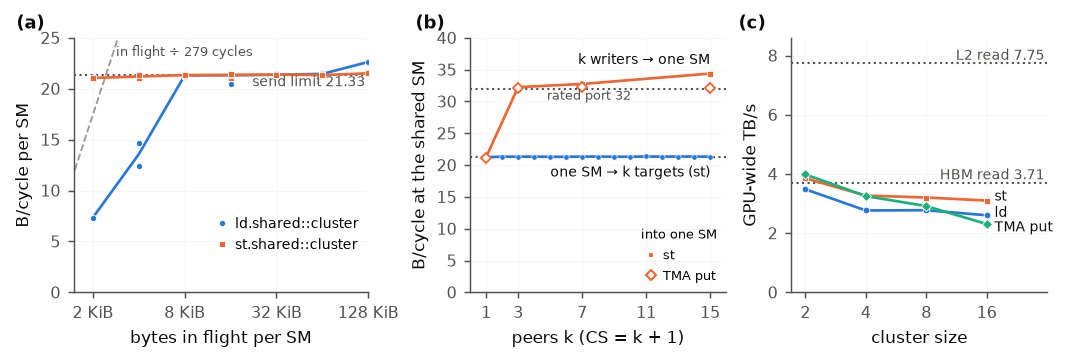

In [10]:
D.fig_dsmem_bandwidth();

**(a) One SM can send at most 21.3 B/cycle (= 64/3; 34.9 GB/s), whatever the operation.** Remote stores reach it with only 2 KiB in flight per SM (e.g. 128 threads × one 16-byte store). Remote loads need 8 KiB in flight: with 2 KiB they reach 7.4 B/cycle, with 4 KiB 13.6. For a load, the *owner* of the data sends the reply, so the limit is charged to the SM being read.

**(b) Send and receive are limited differently.** One SM sending to k = 1…15 targets gets 21.3 B/cycle in total, no more. One SM receiving from 3 or more writers absorbs 32–34 B/cycle. A one-to-many broadcast is therefore bounded by the root's 21.3, while a many-to-one gather runs 1.5× faster per byte at the receiver.

**(c) All clusters together** move 2.3–4.0 TB/s: about the HBM bandwidth and half of the L2 bandwidth. The best case is CS 2 (all 132 SMs busy). Larger clusters lose because of idle SMs (b of the previous figure) and because SMs of one GPC contend: in a ring over 16 SMs of a GPC each SM gets 14.4–15.0 B/cycle for loads (17.1 with 8 SMs) and 17.8–18.6 for stores (20.4 with 8). When both directions are busy, loads lose more (17.1 B/cycle per direction in a ring) because their requests share the sender's budget.

### Atomics on remote shared memory

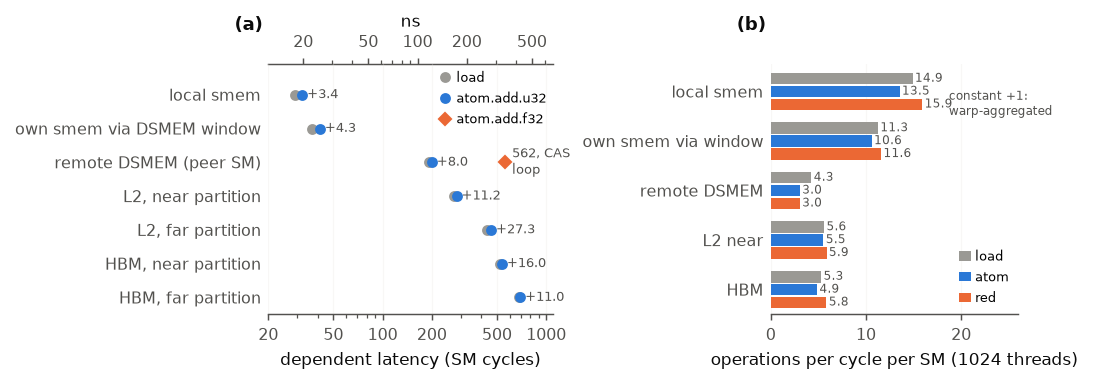

In [11]:
D.fig_dsmem_atomics();

**(a) A remote integer atomic costs only 8 cycles more than a remote load** (the same +8.0 on all 1802 SM pairs), less than the +11 of an L2 atomic or +27 of a far L2 atomic. Floating-point `atom.add.f32` on DSMEM is different: it compiles to a compare-and-swap loop over the network and costs **562 cycles**. 32-bit integer operations (`add/min/max/and/or/xor/exch/cas`) are native on every path; on local shared memory, `add.u64` and all floating-point adds are compare-and-swap loops too (100–122 cycles).

**(b) Throughput per SM.** Remote atomics run at 3.05 operations per cycle per SM (12 B/cycle), below remote loads (4.3) and far below local shared-memory atomics (13.5). A `red.shared.add.u32` with the constant 1 is aggregated per warp by the compiler (`ATOMS.POPC.INC`) and reaches 15.9.

**What this means.**
- Use integer DSMEM atomics for counters and flags: they are as cheap as a load.
- Never use float atomics for remote accumulation. Reduce locally, then push the partial result with a bulk copy, `red.async`, or a TMA reduce (`cp.reduce.async.bulk`).

## 3. TMA: bulk asynchronous copies

### Background
Each SM has one **Tensor Memory Accelerator (TMA)**. A single thread hands it a command: copy N bytes (or a tile of a tensor) from global memory into shared memory, from shared memory to global memory, or from this CTA's shared memory into another CTA's. The TMA then moves the data on its own, bypassing L1 and the registers. Completion is reported on an **mbarrier** in shared memory:
1. the consumer announces how many bytes it expects (`mbarrier.arrive.expect_tx`);
2. the TMA counts the bytes down as they land (`complete_tx`);
3. waiting threads poll `mbarrier.try_wait` until the phase completes.

```cpp
if (threadIdx.x == 0) {
  mbarrier.arrive.expect_tx(bar, bytes);                   // arm: "expect `bytes`"
  cp.async.bulk.shared::cluster.global.mbarrier::complete_tx::bytes [dst], [src], bytes, [bar];
}
while (!mbarrier.try_wait.parity(bar, phase)) {}           // everyone waits for the bytes
```

### How we measured
The latency of one copy is the time from issuing it to seeing its mbarrier phase complete, for 16 B to 64 KiB, from L2-resident and from HBM-resident data. The issue cost is how fast commands can be handed to the TMA back to back.

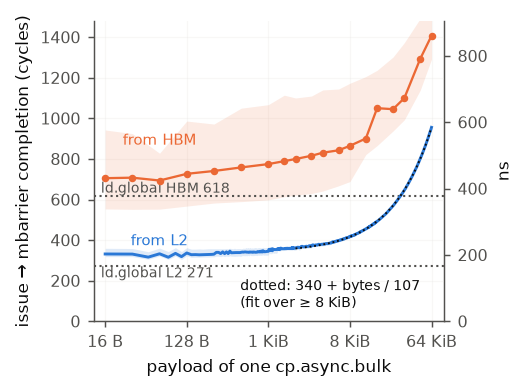

In [12]:
A.fig_tma_copy_latency();

**One copy costs about 340 cycles + bytes / 107 B/cycle.** Up to 1 KiB the time is flat (316–348 cycles from L2); 64 KiB takes 956 cycles. A copy of 16 B from HBM takes 705 cycles. A dependent chain of 16-byte TMA copies is 52 cycles slower than the same chain of plain `ld.global.cg` loads, at both L2 and HBM (323 vs 271, 671 vs 618): that is the cost of the command, the engine and the mbarrier round. The TMA never hits L1.

**Implication.** One copy reaches half of its 107 B/cycle only at about 36 KiB. TMA throughput comes from keeping many copies in flight, not from large single copies; a lone small copy is latency, not bandwidth.

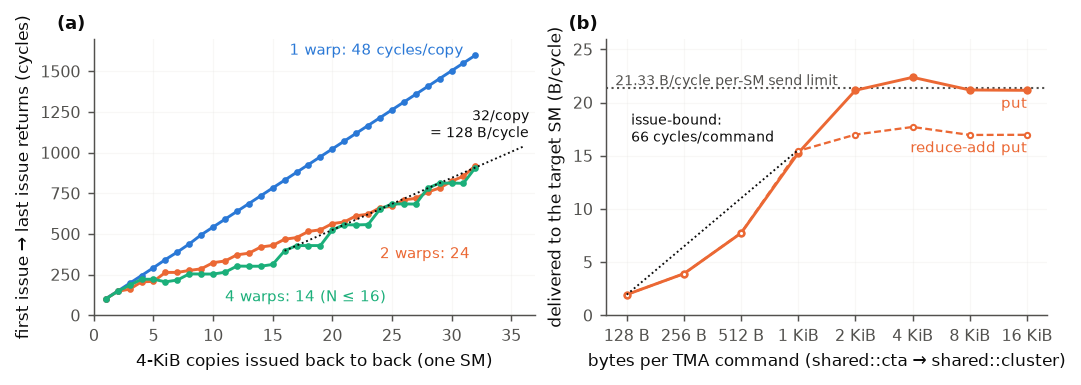

In [13]:
A.fig_tma_issue();

**(a) Issuing copies from global memory.** One warp issues one copy every 48 cycles. Two warps reach 24 cycles per copy and four warps 14, until the engine's 128 B/cycle limit sets in (32 cycles per 4-KiB copy). The data source (L2 or HBM) does not change the issue rate, and more than 50 copies can be outstanding without a stall.

**(b) Shared → shared copies (TMA puts into another CTA).** Up to 1 KiB a command is limited by its issue cost of about 66 cycles: 128 B commands deliver only 1.95 B/cycle, 1 KiB commands 15.3. **From 2 KiB on, a put saturates the 21.3 B/cycle network limit.** The reducing variant (`cp.reduce.async.bulk … .add.u32`) tops out at about 17 B/cycle.

**What this means for DSMEM kernels.**
- Make DSMEM bulk messages at least 2 KiB, or batch several small messages per command.
- A thread that issues one command per destination pays about 66 cycles per destination before the last one leaves. Section 5 shows this is the main cost of fan-out collectives at 8–16 CTAs. Spread fan-out across warps (four warps issue 3.4× faster).
- Use reduce-puts when they remove a local reduction pass, but count on 17 B/cycle, not 21.3.

## 4. Synchronisation

### Background
Producers and consumers need two things: *ordering* (the consumer must see the producer's data) and *notification* (the consumer must know the data is there). The primitives differ in scope and price:
- **CTA scope.** `__syncthreads()` (`bar.sync`): all threads of one block.
- **mbarrier.** A 64-bit object in shared memory with an arrival count and a transaction-byte count. Arrivals and byte completions can come from local threads, remote CTAs or the TMA; waiters poll `try_wait`. It is the completion mechanism of TMA, `st.async` and `red.async`.
- **Cluster barrier.** `barrier.cluster.arrive` + `barrier.cluster.wait` (`cluster.sync()` does both): all threads of all CTAs of the cluster. The default `arrive` has *release* semantics and `wait` *acquire*, so writes before the barrier are visible after it. `arrive.relaxed` only synchronises, without ordering memory.
- **Fences.** `fence.acq_rel.{cta,cluster,gpu}` order memory; `fence.proxy.async` orders ordinary shared-memory writes with the TMA (the "async proxy"), needed before a bulk copy reads data that threads just wrote.
- **Flags.** A store with release semantics and a polling load with acquire semantics, in shared or global memory.

### How we measured
Each primitive is timed with `%clock64` around many back-to-back executions, with 1 to 1024 threads per CTA and cluster sizes 1–16, with and without a preceding store. Hand-offs are ping-pongs between two SMs: SM A signals, SM B waits and replies, and A measures the round trip.

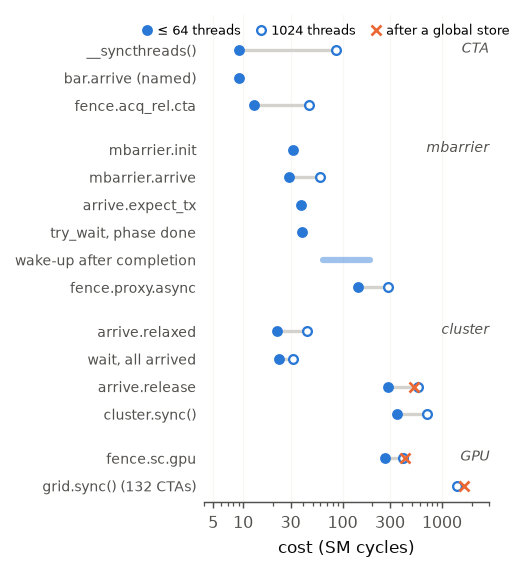

In [14]:
D.fig_sync_costs();

**The price of ordering.**
- **Every release costs a GPU-scope fence**, whatever its nominal scope. A release `arrive`, `st.release.cluster`, `fence.acq_rel.cluster` and `__threadfence()` all compile to the same `MEMBAR.ALL.GPU` sequence; there is no cheaper cluster-scope fence on this chip. It costs 265–284 cycles if the thread made no store since the last fence, and **520–630 cycles if it did** (any store since the last fence, however long ago).
- **Ordering, not rendezvous, is what costs in a cluster barrier.** A relaxed arrive costs 22 cycles and the wait, once everybody has arrived, 23. A full `cluster.sync()` costs 328–354 cycles with up to 128 threads per CTA, 486–519 with 512 and about 700 with 1024: the release arrive scales with the threads that execute it.
- **mbarrier operations are cheap.** `init` 32, `arrive` 29, `arrive.expect_tx` 38, `try_wait` on a completed phase 39 cycles. A waiting thread notices completion 63–189 cycles after it happens.
- `fence.proxy.async` costs 141–287 cycles (more threads, more cost).
- A grid-wide `grid.sync()` costs about 1400 cycles for any number of blocks.

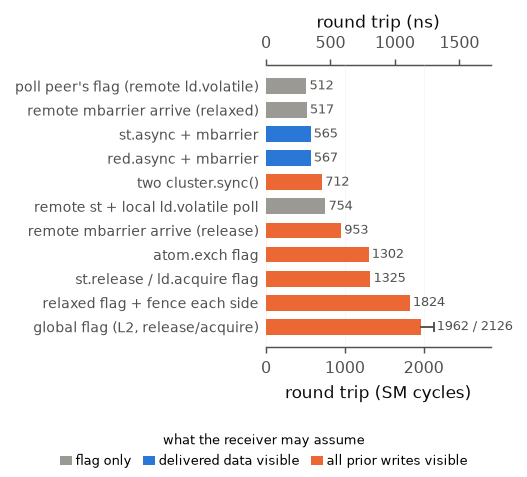

In [15]:
D.fig_handoff();

**Hand-off between two SMs of a cluster** (round trip, CS 2). The bar colour says what the receiver may assume when it sees the signal.
- **`st.async` / `red.async` + mbarrier: 565 cycles round trip (≈ 160 ns one way).** This is the cheapest way to hand over *data*: the store carries its own completion, so no fence is needed on either side. The same holds for TMA puts, which complete on the receiver's mbarrier the same way.
- Signal-only methods are slightly faster (relaxed remote mbarrier arrive 517; polling a peer's flag 512) but order no data.
- Everything with release semantics pays the GPU fence of the previous figure. A release remote arrive takes 953 cycles, a release/acquire flag 1325, and a flag in global memory 1962–2126 (more when its L2 home is in the other partition).
- Polling hand-offs are fragile. The plain-store + poll round trip measured 410–800 cycles in different kernels with the same instruction sequence, depending on how the compiler laid out the poll loop. mbarrier-based hand-offs stayed within 530–619 in every kernel and were the same for every SM pair of the chip (265.5 cycles one way).

**What this means.**
- Hand data over with `st.async`, `red.async` or TMA puts and an mbarrier.
- Avoid release-based flags and, inside loops, avoid cluster barriers after stores: each costs a full GPU fence.
- Use `barrier.cluster.arrive.relaxed` (22 + 23 cycles) where the data has already been published by an mbarrier.

## 5. DSMEM collectives, seen from one SM

### Background
A **collective** combines data held by all CTAs of a cluster. In an **AllReduce**, every CTA ends with the sum of all inputs; in an **AllGather**, with all inputs side by side; in a **ReduceScatter**, with one slice of the sum; in an **AlltoAll**, with the slice every other CTA addressed to it. We implemented 29 algorithms (rings, recursive doubling/halving, Bruck, binomial trees, direct push/pull, two-shot, 2-D mesh, atomics) for clusters of N = 2, 4, 8 and 16 CTAs. Payloads range from 256 B to 227 KiB per CTA, the largest message that fits in shared memory. One cluster runs per launch with 256 threads per CTA.

The algorithms fall into three **synchronisation styles**:
- **mbarrier only.** Each CTA pushes its data with TMA bulk copies to the destinations and waits on its own mbarrier until all expected bytes have arrived. No cluster barrier is needed between phases.
- **One exchange + cluster barriers.** A barrier, one round of remote loads or stores, then a barrier.
- **Cluster barrier every round.** Each round pushes one message with a bulk copy, waits for the incoming one, possibly reduces it locally, and ends with `cluster.sync()` before the buffers are reused.

**How we measured.** Thread 0 of every CTA writes a `%globaltimer` stamp after the entry barrier, after each round and at exit. Global-memory input and output lie outside these stamps. Every configuration ran 2 × 200 timed launches (643 configurations, none discarded). In these runs each SM's timer advanced in 256-ns steps, so a single launch resolves a round only to 256 ns. The phase of those steps is random from launch to launch, so the **mean over the 400 launches** is accurate to about ±6 ns per round; we use means throughout this section.

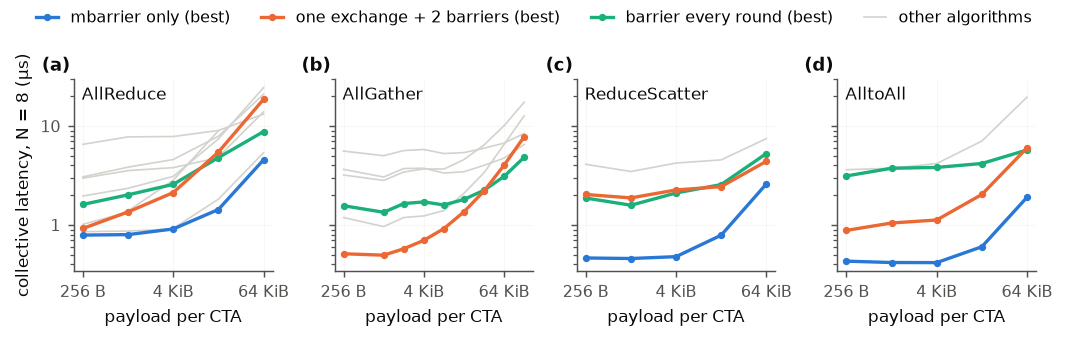

In [16]:
C.fig_coll_latency();

In [17]:
C.best_table()

fastest    µs  cycles  \
collective    payload                                         
AllReduce     256 B                   2d mesh  0.79    1292   
              4 KiB             two-shot push  0.91    1490   
              64 KiB            two-shot push  4.56    7458   
AllGather     256 B    direct replicated push  0.51     836   
              4 KiB    direct replicated push  0.70    1143   
              64 KiB       recursive doubling  3.10    5066   
ReduceScatter 256 B               direct push  0.46     758   
              4 KiB               direct push  0.48     782   
              64 KiB              direct push  2.60    4252   
AlltoAll      256 B               direct push  0.43     704   
              4 KiB               direct push  0.42     681   
              64 KiB              direct push  1.90    3114   

                                     slowest  slowest / fastest  
collective    payload                                            
AllReduce     256 B                     ring                8.3  
              4 KiB                     ring                8.6  
              64 KiB           one-shot pull                5.4  
AllGather     256 B             direct shift               10.9  
              4 KiB             direct shift                8.3  
              64 KiB   gather bcast binomial                3.3  
ReduceScatter 256 B                     ring                8.9  
              4 KiB                     ring                8.8  
              64 KiB                    ring                2.9  
AlltoAll      256 B                    bruck                8.4  
              4 KiB                    bruck               10.0  
              64 KiB                   bruck               10.3

**The synchronisation style decides the latency, not the algorithm's message count.** At N = 8, the fastest mbarrier-only algorithm wins at every payload for AllReduce, ReduceScatter and AlltoAll, by 1.2–4.4× over the best algorithm that uses cluster barriers. AllGather has no mbarrier-only algorithm; there a single exchange with direct remote stores wins up to 32 KiB. Between the fastest and the slowest algorithm of one collective lie factors of 3–11. Below 16 KiB per CTA the curves are almost flat: the time is synchronisation, not data.

### What a barrier and a hand-off cost inside a collective
A least-squares fit over all 102 non-atomic configurations at 256 B, *latency = t₀ + (number of cluster barriers) · t_barrier + (number of mbarrier hand-offs) · t_handoff*, explains 94 % of the variance.

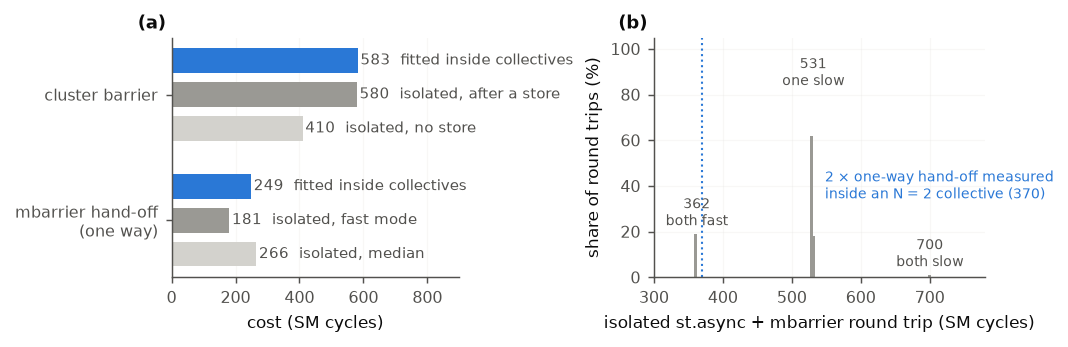

In [18]:
C.fig_sync_effective();

**(a)** Inside the collectives, **one cluster barrier costs 583 cycles**: exactly a release arrive behind earlier stores plus the wait (580 measured in isolation), and 42 % more than a barrier without prior stores (410). Every round of a collective writes data before its barrier, so it always pays the expensive fence. One mbarrier hand-off costs 249 cycles in the fit, which also absorbs the per-round local work.

**(b) A hand-off inside a collective is the fast mode of the isolated one.** The isolated `st.async` ping-pong has three round-trip values over all SM pairs: 362 cycles (both directions fast, 19 %), 531 (one direction one 169-cycle step slower, 80 %) and 700 (both slower, 1 %). A single bulk-copy hand-off measured inside an N = 2 collective takes 185 cycles one way, including arming the mbarrier and issuing the copy. That matches the fast mode, 181. In the ping-pong the receiver waits a whole round trip before its data arrives; in the collective it is still busy with its own copy when the data lands. We therefore price a hand-off at the fast mode, **181 cycles**.

### The per-SM cycle breakdown
For one fixed rank (rank 0; SM 0 for N = 4–8, SM 124 for N = 2, SM 2 for N = 16) we take the measured time of every round and split it into the primitives the round executes on rank 0's critical path, each priced with its isolated cost from sections 1–4 (costs measured at 128 and 512 threads are interpolated to 256):

| segment | cost per occurrence |
|---|---|
| cluster barrier (release after stores + wait) | 544–600 cycles (CS 4–16; 569 at CS 2) |
| hand-off: arm mbarrier, issue the first copy, flight, completion seen | 181 |
| each further copy command issued by the same thread | 65 |
| payload streamed at the 21.3 B/cycle send limit (only the part not hidden behind command issue) | bytes / 21.3 |
| remote loads of the thread's own chain (pull algorithms) | 200 each (37 to its own CTA) |
| local reduce or copy in shared memory (+ `fence.proxy.async`, `__syncthreads`) | per element pass: 33 + bytes moved / 128; fence 157 |

What the isolated costs do not explain remains as a hatched **unattributed** segment: time spent waiting for a slower peer (skew), contention, and first-use effects. When the isolated costs add up to more than the measurement (some steps overlap in reality), the excess is shown faded above the measured line.

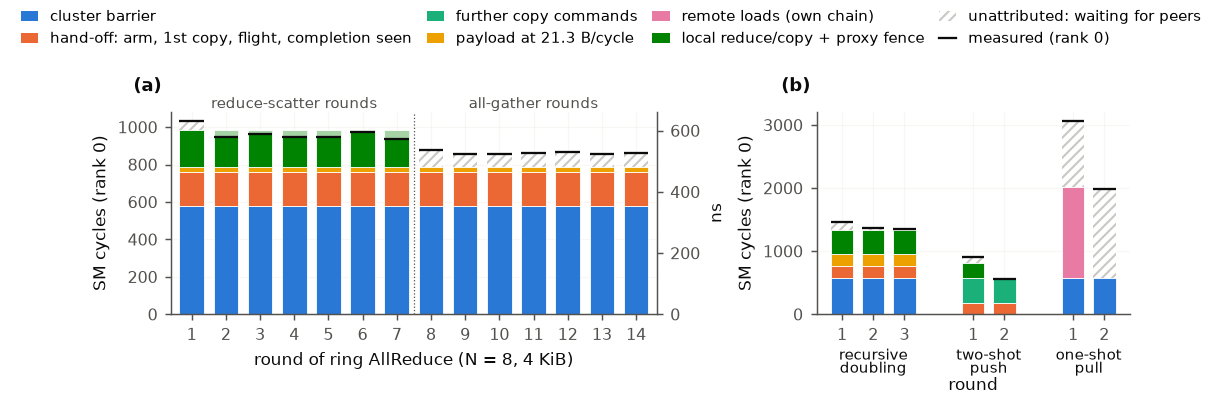

In [19]:
C.fig_breakdown_rounds();

**(a) Ring AllReduce, N = 8, 4 KiB, round by round.**
- Each of the 14 rounds costs 860–1030 cycles, and **580 of them (56–68 %) are the cluster barrier**. The hand-off adds 181 cycles; the 512-byte message itself only 24.
- The seven reduce-scatter rounds add the local reduction and the `fence.proxy.async` that makes the reduced chunk visible to the next bulk copy (≈ 200 cycles). They are about 90 cycles slower than the all-gather rounds.
- The first round is the slowest (1032): ranks enter the collective with some skew.
- The modelled costs explain the measurement within −50…+95 cycles per round.

**(b) Algorithms with few rounds.**
- *Recursive doubling* has the same structure as the ring with three rounds instead of 14, each moving the whole 4 KiB, so each round streams 192 cycles of payload and reduces 1024 elements.
- *Two-shot push* has no cluster barrier. Instead, one thread issues seven copies per shot, and the six further copy commands (390 cycles) dominate.
- *One-shot pull* spends its first segment on the barrier and its thread's chain of 8 serial remote loads (1436 cycles), but still waits about 1000 more cycles, and its closing barrier another 1400. The other warps and CTAs, all reading the same peer at the same time, are slower than thread 0.

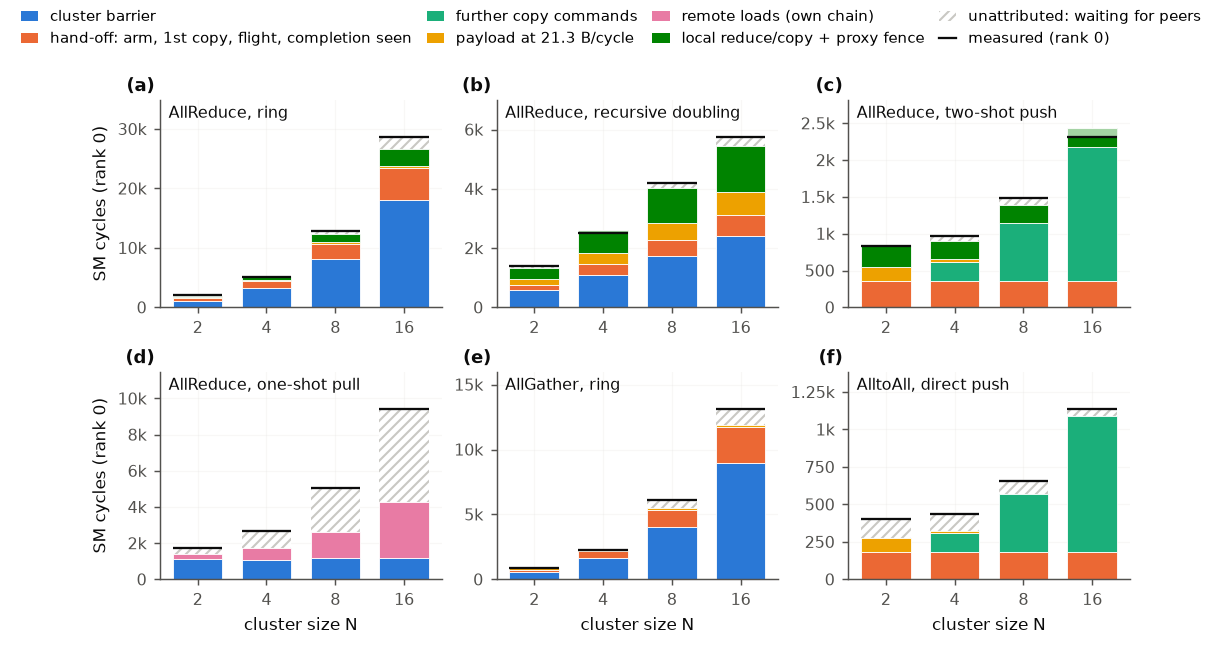

In [20]:
C.fig_breakdown_totals('N');

In [21]:
C.share_table('N')

cycles  cluster barrier  hand-off  \
collective                   N                                       
AlltoAll direct push         2      402                0        45   
                             4      436                0        41   
                             8      658                0        27   
                             16    1136                0        16   
AllReduce one-shot pull      2     1746               65         0   
                             4     2657               41         0   
                             8     5052               23         0   
                             16    9417               13         0   
AllReduce recursive doubling 2     1388               41        13   
                             4     2513               42        14   
                             8     4196               41        13   
                             16    5749               42        13   
AllGather ring               2      897               63        20   
                             4     2273               70        23   
                             8     6105               67        21   
                             16   13118               69        21   
AllReduce ring               2     2017               56        18   
                             4     5100               62        21   
                             8    12797               63        20   
                             16   28657               63        19   
AllReduce two-shot push      2      836                0        43   
                             4      969                0        37   
                             8     1480                0        24   
                             16    2314                0        15   

                                 further copy commands  \
collective                   N                           
AlltoAll direct push         2                       0   
                             4                      30   
                             8                      59   
                             16                     80   
AllReduce one-shot pull      2                       0   
                             4                       0   
                             8                       0   
                             16                      0   
AllReduce recursive doubling 2                       0   
                             4                       0   
                             8                       0   
                             16                      0   
AllGather ring               2                       0   
                             4                       0   
                             8                       0   
                             16                      0   
AllReduce ring               2                       0   
                             4                       0   
                             8                       0   
                             16                      0   
AllReduce two-shot push      2                       0   
                             4                      27   
                             8                      53   
                             16                     75   

                                 payload at 21.3 B/cycle  remote loads  \
collective                   N                                           
AlltoAll direct push         2                        24             0   
                             4                         3             0   
                             8                         0             0   
                             16                        0             0   
AllReduce one-shot pull      2                         0            14   
                             4                         0            24   
                             8                         0            28   
                             16      

**Varying the cluster size at 4 KiB per CTA** (whole collective, rank 0; the table gives the shares in %):
- **Ring AllReduce and ring AllGather grow linearly with N, and 56–70 % of their time is cluster barriers.** The ring's 2(N−1) rounds each pay a 580-cycle barrier. At N = 16 that is 30 barriers or about 18,000 cycles: 7.8× the entire two-shot AllReduce of the same size.
- **Recursive doubling** needs only log₂N rounds. Its time is spread over barrier (41 %), local reduce + fence (28 %), payload (14 %) and hand-off (13 %).
- **Two-shot push and direct-push AlltoAll** grow with N because one thread issues N−1 copy commands per phase: at N = 16 the command issue is **75–80 % of their time**. This is the term to attack, by spreading the commands of one CTA over several warps or by letting several CTAs forward.
- **One-shot pull** is dominated by remote-load chains and unattributed waiting (49–55 % at N ≥ 8). Its loads go one at a time per thread (each thread reads the N peers in sequence), far below the 8 KiB in flight that DSMEM loads need.

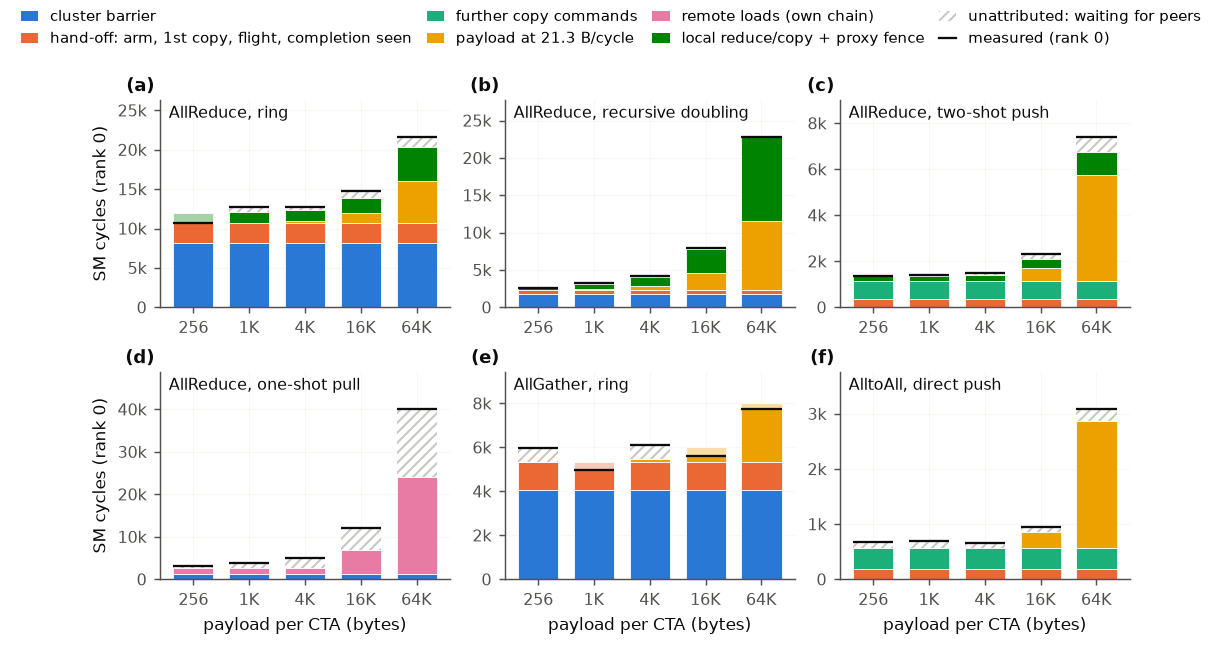

In [22]:
C.fig_breakdown_totals('payload');

In [23]:
C.share_table('payload')

cycles  cluster barrier  hand-off  \
collective                   payload                                      
AlltoAll direct push         256 B       686                0        26   
                             4 KiB       658                0        27   
                             64 KiB     3088                0         6   
AllReduce one-shot pull      256 B      3200               36         0   
                             4 KiB      5052               23         0   
                             64 KiB    40078                3         0   
AllReduce recursive doubling 256 B      2649               60        19   
                             4 KiB      4196               41        13   
                             64 KiB    22798                8         2   
AllGather ring               256 B      5966               68        21   
                             4 KiB      6105               67        21   
                             64 KiB     7748               51        16   
AllReduce ring               256 B     10705               68        21   
                             4 KiB     12797               63        20   
                             64 KiB    21623               38        12   
AllReduce two-shot push      256 B      1382                0        26   
                             4 KiB      1480                0        24   
                             64 KiB     7403                0         5   

                                      further copy commands  \
collective                   payload                          
AlltoAll direct push         256 B                       57   
                             4 KiB                       59   
                             64 KiB                      13   
AllReduce one-shot pull      256 B                        0   
                             4 KiB                        0   
                             64 KiB                       0   
AllReduce recursive doubling 256 B                        0   
                             4 KiB                        0   
                             64 KiB                       0   
AllGather ring               256 B                        0   
                             4 KiB                        0   
                             64 KiB                       0   
AllReduce ring               256 B                        0   
                             4 KiB                        0   
                             64 KiB                       0   
AllReduce two-shot push      256 B                       56   
                             4 KiB                       53   
                             64 KiB                      11   

                                      payload at 21.3 B/cycle  remote loads  \
collective                   payload                                          
AlltoAll direct push         256 B                          0             0   
                             4 KiB                          0             0   
                             64 KiB                        74             0   
AllReduce one-shot pull      256 B                          0            45   
                             4 KiB                          0            28   
                             64 KiB                         0            57   
AllReduce recursive doubling 256 B                          1             0   
                             4 KiB                         14             0   
                             64 KiB                        40             0   
AllGather ring               256 B                          0             0   
                             4 KiB                          3             0   
                             64 KiB                        34             0   
AllReduce ring               256 B                          0             0   
                             4 KiB                          3             0   
            

**Varying the payload at N = 8.** Up to 4 KiB per CTA the breakdown does not change: the payload term stays below 3 % for every push algorithm. It becomes visible at 16 KiB and dominates the mbarrier-only algorithms at 64 KiB (62–74 %). For barrier-based algorithms at 64 KiB, synchronisation still takes 38–51 % in the ring. Recursive doubling, which sends the whole buffer every round, becomes reduction- and transfer-bound (90 %).

**How well do the isolated costs explain the measurements?** Over all payloads and cluster sizes, the composed costs reproduce a median of 94–98 % of rank 0's measured time for the ring, recursive doubling and two-shot algorithms. They reproduce 75 % for the direct-push AlltoAll, where the smallest clusters pay about 110 cycles of first-use cost after the entry barrier, and 63 % for the pull AllReduce, whose unattributed share is contention among simultaneous readers.

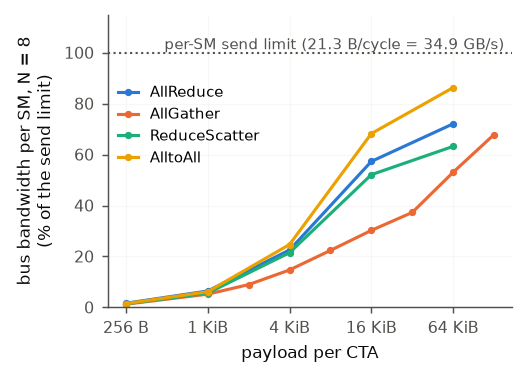

In [24]:
C.fig_coll_bandwidth();

**Bandwidth.** The *bus bandwidth* per SM (bytes each SM must send for the collective, divided by its latency) of the best algorithm at N = 8 rises with the payload. It reaches 72 % (AllReduce two-shot), 63 % (ReduceScatter direct push), 86 % (AlltoAll direct push) and 68 % (AllGather Bruck at 128 KiB) of the 21.3 B/cycle send limit. Collectives therefore approach the network limit only with tens of KiB per CTA; at 4 KiB they reach only 15–25 % of it.

## 6. Takeaways for DSMEM kernel design

1. **Use clusters for latency and locality, not for bandwidth.** A remote shared-memory load costs about 200 cycles, the same at every cluster size: 0.75× a near L2 hit and 0.47× a far one. But an SM can send only 21.3 B/cycle into the network, less than it reads from L2 on its own (82), and all clusters together move 2.3–4.0 TB/s, about the HBM bandwidth.
2. **Choose the cluster size for occupancy.** Latency is flat in the cluster size and placement inside a GPC is worth at most 36 cycles. CS 2 keeps all 132 SMs busy; CS 4/8 leave 12 idle; CS 16 leaves 20 idle (15 %) and suffers 10–15 % contention when all 16 SMs of a GPC exchange.
3. **Push, don't pull.** Stores, `st.async` and TMA puts reach the send limit with 2 KiB in flight per SM; loads need 8 KiB, and their replies consume the owner's send budget. Pull loops with one outstanding load per thread are the slowest collectives we measured.
4. **Hand over data with `st.async`, `red.async` or TMA puts and an mbarrier** (181 cycles one way inside a collective, 565 round trip in isolation). Release/acquire flags cost 1325 cycles and global-memory flags about 2000.
5. **Treat a cluster barrier as a 580-cycle GPU fence** once any store happened before it. In a ring AllReduce barriers take 56–70 % of the time. Replace per-round barriers by per-buffer mbarriers, or use relaxed arrive + wait (45 cycles) where an mbarrier already published the data.
6. **Do not let one thread issue every bulk copy.** Each further shared→shared command costs about 65 cycles on the issuing thread; at N = 16 this is 75–80 % of two-shot AllReduce and direct-push AlltoAll. Make each command ≥ 2 KiB and spread commands over warps.
7. **Below 16 KiB per CTA, collective time is synchronisation and issue.** The bytes matter only above that. Choose algorithms by their number of synchronisation steps first: mbarrier-only algorithms are 1.2–4.4× faster than the best algorithm with cluster barriers, and up to 11× faster than the slowest.
8. **Reduce locally; use integer remote atomics only for counters.** A remote `add.u32` costs a load + 8 cycles, but runs at 3 operations/cycle per SM, and `add.f32` is a 562-cycle compare-and-swap loop.

## Limitations
- The cycle breakdown is a model. It composes costs measured in isolation along rank 0's critical path and shows explicitly what it does not explain. Overlaps between steps (for instance, the local copy of the AlltoAll running while data arrives) are approximated.
- Collective stamps are written by thread 0 of each CTA. Work of other warps shows up only when thread 0 waits for it, at the next barrier or mbarrier.
- All collectives ran as a single cluster on an otherwise idle GPU with 256 threads per CTA. Many concurrent clusters add the GPC contention of section 2.
- Two cards of the same model were used. Their topology and cluster placement were measured identical; their L2 partition grouping differs (GPCs 4 and 7), which does not change any number shown here.